# Single-Wave Reconstruction: SHRED vs SDN vs Gappy POD

Trains SHRED and SDN on **one trajectory** of the repository's synthetic 1D wave
dataset and compares them with the linear gappy-POD (QR/POD) baseline, for a small
sweep of sensor counts.

Everything is taken from the repository where possible:

- `load_dataset` for the data
- `split_window_indices` for the interleaved train/validation/test split
- `qr_place` for QR sensor placement and the POD basis
- `build_sensor_windows` for the lagged sensor windows
- `SHRED`, `SDN`, `TimeSeriesDataset`, `fit` for the networks and training
- `qrpod_reconstruct` for the gappy-POD baseline

The pipeline mirrors `run_experiment()` (same split, scaling, placement, training
call, and baseline), but keeps the trained models and test indices so individual
test snapshots can be plotted at their physical time.

## Interpretation notes

- The split is **interleaved**, so this is an *interpolatory reconstruction*
  experiment, not a forecasting one. Neighbouring windows overlap heavily.
- The wave data is a sum of exactly 10 sine modes. Gappy POD with `k` sensors uses
  `k` POD modes, so at 10 sensors it can be (near-)exact. That is expected, not a bug.
- No LR scheduler: `fit()` is used unchanged (Adam, MSE, early stopping).

In [19]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.preprocessing import MinMaxScaler


# ------------------------------------------------------------------
# Locate repository root
# ------------------------------------------------------------------

repo_root = Path.cwd().resolve()

if not (repo_root / "src" / "get_shredded").exists():
    repo_root = repo_root.parent

if not (repo_root / "src" / "get_shredded").exists():
    raise FileNotFoundError(
        "Could not find the repository's src/get_shredded directory. "
        "Run this notebook from the repository root or from prototyping_tests/."
    )

src_dir = repo_root / "src"

if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))


# ------------------------------------------------------------------
# Repository imports
# ------------------------------------------------------------------

from get_shredded import SDN, SHRED, TimeSeriesDataset, fit

from get_shredded.data import (
    build_sensor_windows,
    load_dataset,
    qr_place,
    qrpod_reconstruct,
)

from get_shredded.experiment import (
    _aggregate_rel_error,
    _per_snapshot_rel_error,
    split_window_indices,
)

print(f"Repository root: {repo_root}")

Repository root: /Users/kaspervanderhorst/projects/shred/get-shredded


In [20]:
# ------------------------------------------------------------------
# Experiment configuration
# ------------------------------------------------------------------

# Data
TRAJECTORY_INDEX = 1

# Sensors / windows
SENSOR_COUNTS = [3, 5, 10]
LAGS = 25
PLACEMENT = "QR"          # "QR" or "random"

# Split
TRAIN_PCT = 80
VAL_PCT = 10
TEST_PCT = 10

# Seed
SEED = 42

# Model
HIDDEN_SIZE = 64
HIDDEN_LAYERS = 2
L1 = 350
L2 = 400
DROPOUT = 0.0
RECURRENT_CELL = "gru"

# Training
MAX_EPOCHS = 1000
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
PATIENCE = 5
VERBOSE_TRAINING = True

# Plotting
SELECTED_TEST_INDEX = 26
CLIP_YLIM_TO_TRUTH = True

METHODS = ["SHRED", "SDN", "Gappy POD"]

In [21]:
# ------------------------------------------------------------------
# Load one trajectory with the repository dataloader
# ------------------------------------------------------------------

data_path = repo_root / "data" / "wave_1d.npz"

if not data_path.exists():
    raise FileNotFoundError(
        f"{data_path} not found. Generate it with:\n"
        "  uv run python prototyping_tests/generate_wave_data.py"
    )

wave, nx, ny = load_dataset(
    "wave",
    data_path,
    trajectory_index=TRAJECTORY_INDEX,
)

n_time, n_state = wave.shape

with np.load(data_path) as payload:
    x = np.asarray(payload["x"], dtype=np.float64)
    t = np.asarray(payload["t"], dtype=np.float64)

if max(SENSOR_COUNTS) > n_state:
    raise ValueError(
        f"max(SENSOR_COUNTS)={max(SENSOR_COUNTS)} exceeds "
        f"n_state={n_state}."
    )

print(
    f"Wave shape: {wave.shape}  "
    f"(n_time={n_time}, n_state={n_state})"
)

print(
    f"x in [{x.min():.3f}, {x.max():.3f}],  "
    f"t in [{t.min():.3f}, {t.max():.3f}]"
)

Wave shape: (500, 256)  (n_time=500, n_state=256)
x in [0.000, 2.000],  t in [0.000, 2.000]


In [22]:
# ------------------------------------------------------------------
# Interleaved split of the lagged windows
# ------------------------------------------------------------------

n_windows = n_time - LAGS

train_idx, valid_idx, test_idx = split_window_indices(
    n_windows,
    train_percentage=TRAIN_PCT,
    val_percentage=VAL_PCT,
    test_percentage=TEST_PCT,
    seed=SEED,
)

# A window i covers snapshots:
# i ... i + LAGS - 1
#
# Its target is therefore:
# i + LAGS - 1

test_snapshot_idx = test_idx + LAGS - 1

if not 0 <= SELECTED_TEST_INDEX < len(test_idx):
    raise IndexError(
        f"SELECTED_TEST_INDEX={SELECTED_TEST_INDEX} invalid; "
        f"choose 0..{len(test_idx) - 1}."
    )

print(
    f"Windows: total={n_windows}, "
    f"train={len(train_idx)}, "
    f"valid={len(valid_idx)}, "
    f"test={len(test_idx)}"
)

Windows: total=475, train=380, valid=48, test=47


In [23]:
# ------------------------------------------------------------------
# Device
# ------------------------------------------------------------------

if torch.cuda.is_available():
    device = "cuda"

else:
    device = "cpu"

print(f"Using device: {device}")

Using device: cpu


In [24]:
# ------------------------------------------------------------------
# One full run for a given sensor count
# ------------------------------------------------------------------

def run_one(num_sensors: int) -> dict:
    """
    Place sensors, train SHRED and SDN, run gappy POD,
    and evaluate on the test set.
    """

    np.random.seed(SEED)
    torch.manual_seed(SEED)

    # --------------------------------------------------------------
    # Sensor placement + POD basis
    # --------------------------------------------------------------

    if PLACEMENT == "QR":

        sensor_locations, U_r = qr_place(
            wave[train_idx].T,
            num_sensors,
        )

    else:

        _, U_r = qr_place(
            wave[train_idx].T,
            num_sensors,
        )

        sensor_locations = np.random.choice(
            n_state,
            size=num_sensors,
            replace=False,
        )

    sensor_locations = np.asarray(sensor_locations)

    # --------------------------------------------------------------
    # Scale data using training data only
    # --------------------------------------------------------------

    scaler = MinMaxScaler().fit(
        wave[train_idx]
    )

    transformed = scaler.transform(
        wave
    ).astype(np.float32)

    # --------------------------------------------------------------
    # Build lagged sensor windows
    # --------------------------------------------------------------

    windows = build_sensor_windows(
        transformed,
        sensor_locations,
        LAGS,
    )

    def to_tensor(arr: np.ndarray) -> torch.Tensor:
        return torch.tensor(
            arr,
            dtype=torch.float32,
            device=device,
        )

    # --------------------------------------------------------------
    # Inputs
    # --------------------------------------------------------------

    train_in, valid_in, test_in = (
        to_tensor(windows[i])
        for i in (train_idx, valid_idx, test_idx)
    )

    # --------------------------------------------------------------
    # Targets
    # --------------------------------------------------------------

    train_out, valid_out, test_out = (
        to_tensor(
            transformed[i + LAGS - 1]
        )
        for i in (train_idx, valid_idx, test_idx)
    )

    # --------------------------------------------------------------
    # SHRED datasets
    # --------------------------------------------------------------

    shred_train = TimeSeriesDataset(
        train_in,
        train_out,
    )

    shred_valid = TimeSeriesDataset(
        valid_in,
        valid_out,
    )

    # --------------------------------------------------------------
    # SDN datasets
    #
    # SDN only sees the latest sensor snapshot.
    # --------------------------------------------------------------

    sdn_train = TimeSeriesDataset(
        train_in[:, -1, :],
        train_out,
    )

    sdn_valid = TimeSeriesDataset(
        valid_in[:, -1, :],
        valid_out,
    )

    # --------------------------------------------------------------
    # SHRED
    # --------------------------------------------------------------

    shred = SHRED(
        num_sensors,
        n_state,
        hidden_size=HIDDEN_SIZE,
        hidden_layers=HIDDEN_LAYERS,
        l1=L1,
        l2=L2,
        dropout=DROPOUT,
        recurrent_cell=RECURRENT_CELL,
    ).to(device)

    shred_hist = fit(
        shred,
        shred_train,
        shred_valid,
        batch_size=BATCH_SIZE,
        num_epochs=MAX_EPOCHS,
        lr=LEARNING_RATE,
        verbose=VERBOSE_TRAINING,
        patience=PATIENCE,
    )

    # --------------------------------------------------------------
    # SDN
    # --------------------------------------------------------------

    sdn = SDN(
        num_sensors,
        n_state,
        l1=L1,
        l2=L2,
        dropout=DROPOUT,
    ).to(device)

    sdn_hist = fit(
        sdn,
        sdn_train,
        sdn_valid,
        batch_size=BATCH_SIZE,
        num_epochs=MAX_EPOCHS,
        lr=LEARNING_RATE,
        verbose=VERBOSE_TRAINING,
        patience=PATIENCE,
    )

    # --------------------------------------------------------------
    # Test-set reconstructions
    # --------------------------------------------------------------

    shred.eval()
    sdn.eval()

    with torch.no_grad():

        shred_recon = scaler.inverse_transform(
            shred(test_in).cpu().numpy()
        )

        sdn_recon = scaler.inverse_transform(
            sdn(test_in[:, -1, :]).cpu().numpy()
        )

    truth = scaler.inverse_transform(
        test_out.cpu().numpy()
    )

    # --------------------------------------------------------------
    # Gappy POD
    #
    # Uses unscaled sensor measurements at the target snapshots.
    # --------------------------------------------------------------

    pod_recon = qrpod_reconstruct(
        wave[test_snapshot_idx][:, sensor_locations],
        sensor_locations,
        U_r,
        n_state,
    )

    # --------------------------------------------------------------
    # Collect reconstructions
    # --------------------------------------------------------------

    recons = {
        "SHRED": shred_recon,
        "SDN": sdn_recon,
        "Gappy POD": pod_recon,
    }

    return {
        "num_sensors": num_sensors,
        "sensor_locations": sensor_locations,
        "truth": truth,
        "recons": recons,

        "global_err": {
            name: _aggregate_rel_error(recon, truth)
            for name, recon in recons.items()
        },

        "per_snap_err": {
            name: _per_snapshot_rel_error(recon, truth)
            for name, recon in recons.items()
        },

        "val_history": {
            "SHRED": shred_hist.numpy(),
            "SDN": sdn_hist.numpy(),
        },
    }

In [25]:
# ------------------------------------------------------------------
# Run the sweep
# ------------------------------------------------------------------

results: dict[int, dict] = {}

for ns in SENSOR_COUNTS:

    print(
        f"\n=== {ns} sensors ({PLACEMENT} placement) ==="
    )

    results[ns] = run_one(ns)

    for name in ("SHRED", "SDN"):

        hist = results[ns]["val_history"][name]

        print(
            f"{name}: best validation error "
            f"{hist.min():.6f} "
            f"({len(hist)} validation checks)"
        )


=== 3 sensors (QR placement) ===


train SHRED:   0%|          | 0/1000 [00:00<?, ?it/s]

train SDN:   0%|          | 0/1000 [00:00<?, ?it/s]

SHRED: best validation error 0.007457 (18 validation checks)
SDN: best validation error 0.006639 (49 validation checks)

=== 5 sensors (QR placement) ===


train SHRED:   0%|          | 0/1000 [00:00<?, ?it/s]

train SDN:   0%|          | 0/1000 [00:00<?, ?it/s]

SHRED: best validation error 0.007153 (20 validation checks)
SDN: best validation error 0.005734 (28 validation checks)

=== 10 sensors (QR placement) ===


train SHRED:   0%|          | 0/1000 [00:00<?, ?it/s]

train SDN:   0%|          | 0/1000 [00:00<?, ?it/s]

SHRED: best validation error 0.003540 (42 validation checks)
SDN: best validation error 0.002999 (24 validation checks)


In [26]:
# ------------------------------------------------------------------
# Test-set metrics table
# ------------------------------------------------------------------

# "global" =
# ||recon - truth|| / ||truth||
# over the whole test set.
#
# mean / median / max =
# statistics over per-snapshot relative L2 errors.

header = (
    f"{'sensors':>7}  "
    f"{'method':<10} "
    f"{'global L2':>10} "
    f"{'mean':>10} "
    f"{'median':>10} "
    f"{'max':>10}"
)

print(
    f"Test set: {len(test_idx)} snapshots, "
    f"trajectory {TRAJECTORY_INDEX}, seed {SEED}"
)

print(header)
print("-" * len(header))

for ns, res in results.items():

    for name in METHODS:

        e = res["per_snap_err"][name]

        print(
            f"{ns:>7}  "
            f"{name:<10} "
            f"{res['global_err'][name]:>10.5f} "
            f"{e.mean():>10.5f} "
            f"{np.median(e):>10.5f} "
            f"{e.max():>10.5f}"
        )

    print()

Test set: 47 snapshots, trajectory 1, seed 42
sensors  method      global L2       mean     median        max
---------------------------------------------------------------
      3  SHRED         0.01448    0.01682    0.01298    0.06787
      3  SDN           0.01464    0.01687    0.01052    0.07743
      3  Gappy POD     0.27771    0.33420    0.27209    0.90749

      5  SHRED         0.01448    0.01805    0.01256    0.05741
      5  SDN           0.01034    0.01287    0.00929    0.03826
      5  Gappy POD     0.19391    0.22929    0.18695    0.84024

     10  SHRED         0.00698    0.00807    0.00639    0.02664
     10  SDN           0.00553    0.00705    0.00529    0.02603
     10  Gappy POD     0.00000    0.00000    0.00000    0.00000



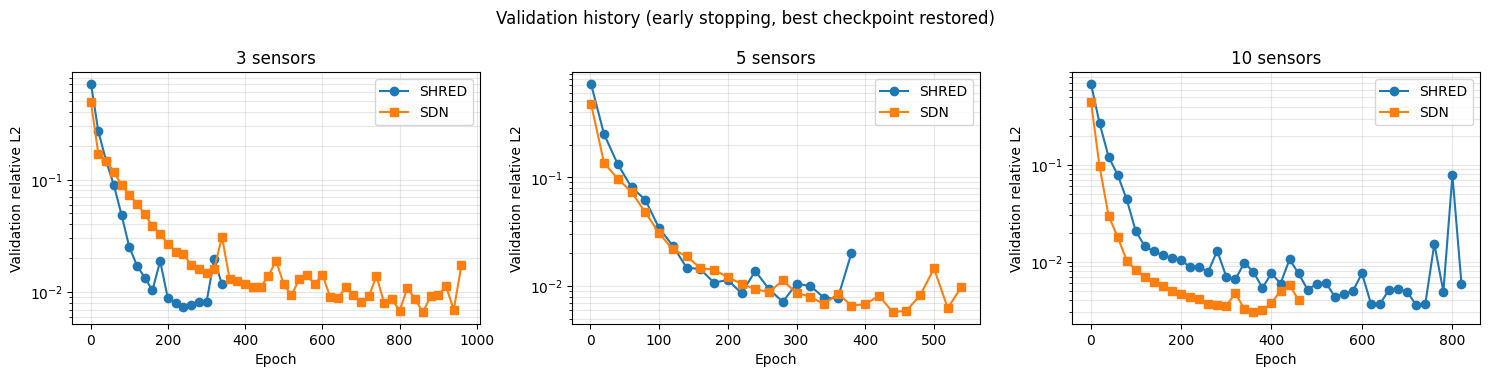

In [27]:
# ------------------------------------------------------------------
# Training curves
# ------------------------------------------------------------------

def validation_epochs(history: np.ndarray) -> np.ndarray:
    """
    fit() validates at epoch 1 and then every 20 epochs:

        1, 20, 40, 60, ...

    """
    return np.r_[
        1,
        20 * np.arange(1, len(history))
    ]


fig, axes = plt.subplots(
    1,
    len(SENSOR_COUNTS),
    figsize=(5 * len(SENSOR_COUNTS), 3.8),
    squeeze=False,
)

for ax, ns in zip(axes[0], SENSOR_COUNTS):

    for name, marker in (
        ("SHRED", "o"),
        ("SDN", "s"),
    ):

        hist = results[ns]["val_history"][name]

        ax.plot(
            validation_epochs(hist),
            hist,
            marker=marker,
            linewidth=1.5,
            label=name,
        )

    ax.set_yscale("log")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Validation relative L2")
    ax.set_title(f"{ns} sensors")
    ax.grid(alpha=0.3, which="both")
    ax.legend()


fig.suptitle(
    "Validation history "
    "(early stopping, best checkpoint restored)"
)

fig.tight_layout()

plt.show()

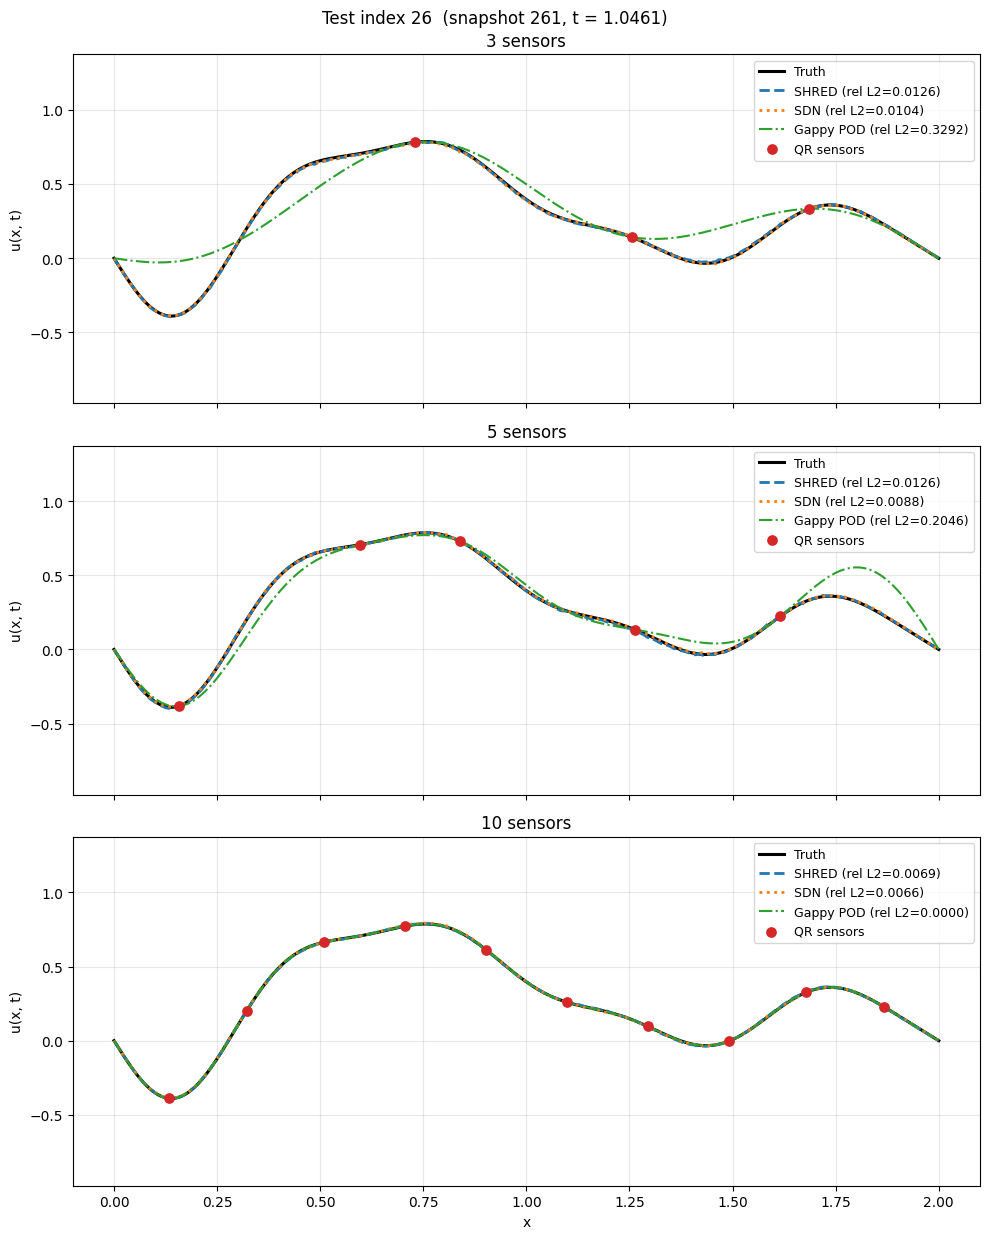

In [28]:
# ------------------------------------------------------------------
# Selected test snapshot:
# Truth vs SHRED vs SDN vs Gappy POD
# ------------------------------------------------------------------

sel = SELECTED_TEST_INDEX

sel_snapshot = int(
    test_snapshot_idx[sel]
)

sel_time = float(
    t[sel_snapshot]
)


fig, axes = plt.subplots(
    len(SENSOR_COUNTS),
    1,
    figsize=(10, 4.2 * len(SENSOR_COUNTS)),
    squeeze=False,
    sharex=True,
)


styles = {
    "SHRED": dict(
        linestyle="--",
        linewidth=2,
    ),

    "SDN": dict(
        linestyle=":",
        linewidth=2,
    ),

    "Gappy POD": dict(
        linestyle="-.",
        linewidth=1.5,
    ),
}


for ax, ns in zip(
    axes[:, 0],
    SENSOR_COUNTS,
):

    res = results[ns]

    truth_snap = res["truth"][sel]

    # --------------------------------------------------------------
    # Truth
    # --------------------------------------------------------------

    ax.plot(
        x,
        truth_snap,
        color="black",
        linewidth=2.2,
        label="Truth",
    )

    # --------------------------------------------------------------
    # Reconstructions
    # --------------------------------------------------------------

    for name in METHODS:

        err = res["per_snap_err"][name][sel]

        ax.plot(
            x,
            res["recons"][name][sel],
            label=f"{name} (rel L2={err:.4f})",
            **styles[name],
        )

    # --------------------------------------------------------------
    # Sensor locations
    # --------------------------------------------------------------

    ax.scatter(
        x[res["sensor_locations"]],
        truth_snap[res["sensor_locations"]],
        s=45,
        color="tab:red",
        zorder=4,
        label=(
            "QR sensors"
            if PLACEMENT == "QR"
            else "Sensors"
        ),
    )

    # --------------------------------------------------------------
    # Optional y-axis clipping
    # --------------------------------------------------------------

    if CLIP_YLIM_TO_TRUTH:

        lo = truth_snap.min()
        hi = truth_snap.max()

        pad = 0.5 * (hi - lo)

        ax.set_ylim(
            lo - pad,
            hi + pad,
        )

    ax.set_ylabel("u(x, t)")
    ax.set_title(f"{ns} sensors")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)


axes[-1, 0].set_xlabel("x")

fig.suptitle(
    f"Test index {sel}  "
    f"(snapshot {sel_snapshot}, "
    f"t = {sel_time:.4f})"
)

fig.tight_layout()

plt.show()